### 1. Inicialização e Configuração
Esta célula centraliza todos os *imports* do projeto, inicializa a configuração central (`Config`), carrega as anotações de validação do *dataset* WIDER FACE e instancia os módulos base do *pipeline*.

In [2]:
%load_ext autoreload
%autoreload 2

import os
import glob
import time
import random
from collections import defaultdict

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from retinaface import RetinaFace

from src.core.config import Config
from src.vision.detection import FaceDetector
from src.vision.alignment import FaceAligner
from src.vision.attributes import AgeGenderEstimator
from src.vision.recognition import ExpressionRecognizer, canonicalize_expression
from src.vision.identity import IdentityRecognizer
from src.utils.evaluation import (
    AGE_GROUPS,
    get_age_group,
    parse_wider_face_val,
    parse_wider_face_val_detailed,
    evaluate_image_detections,
    evaluate_detection_robustness,
    evaluate_age_gender_metrics,
    evaluate_expression_metrics,
    calibrate_identity_threshold,
    evaluate_identity_metrics,
)

# 1. Carregar configurações
cfg = Config()

# 2. Carregar anotações Ground Truth do WIDER FACE (básicas e detalhadas)
val_annotations = parse_wider_face_val(cfg.wider_face_gt_path, cfg.wider_face_img_dir)
val_detailed = parse_wider_face_val_detailed(cfg.wider_face_gt_path, cfg.wider_face_img_dir)
print(f"Total de imagens carregadas para validação: {len(val_annotations)}")

# 3. Inicializar o detetor e o alinhador
detector = FaceDetector(
    model_name=cfg.det_model_name,
    det_thresh=cfg.det_thresh,
    use_gpu=False,
)
aligner = FaceAligner(crop_size=112)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Total de imagens carregadas para validação: 3226


### 2. Avaliação do Detetor Facial (WIDER FACE)
Aqui executamos a deteção numa amostra de imagens de validação e calculamos a precisão (*Precision*) e revocação (*Recall*) medindo a sobreposição (*Intersection over Union - IoU*) entre as caixas detetadas e as reais. Também extraímos o tempo médio de inferência.

In [ ]:
print("=== Benchmark de Detetores: SCRFD vs RetinaFace ===")
print("A carregar imagens do WIDER FACE...\n")

test_subset = list(val_annotations.keys())[:100]

# Dicionários para guardar previsões e reutilizar na Célula 2.1 (robustez)
preds_scrfd = {}
preds_retina = {}

# --- 1. Avaliar SCRFD (buffalo_l) ---
tp_scrfd, fp_scrfd, fn_scrfd = 0, 0, 0
start_time = time.time()

for img_path in test_subset:
    frame = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    faces, _ = detector.detect(frame)

    pred_boxes = [f["bbox"] for f in faces]
    preds_scrfd[img_path] = pred_boxes

    tp, fp, fn = evaluate_image_detections(pred_boxes, val_annotations[img_path])
    tp_scrfd += tp
    fp_scrfd += fp
    fn_scrfd += fn

ms_scrfd = ((time.time() - start_time) / len(test_subset)) * 1000
precision_scrfd = tp_scrfd / (tp_scrfd + fp_scrfd) if (tp_scrfd + fp_scrfd) > 0 else 0.0
recall_scrfd = tp_scrfd / (tp_scrfd + fn_scrfd) if (tp_scrfd + fn_scrfd) > 0 else 0.0

# --- 2. Avaliar RetinaFace ---
tp_retina, fp_retina, fn_retina = 0, 0, 0
start_time = time.time()

for img_path in test_subset:
    resp = RetinaFace.detect_faces(img_path)
    pred_boxes = [resp[k]["facial_area"] for k in resp] if isinstance(resp, dict) else []
    preds_retina[img_path] = pred_boxes

    tp, fp, fn = evaluate_image_detections(pred_boxes, val_annotations[img_path])
    tp_retina += tp
    fp_retina += fp
    fn_retina += fn

ms_retina = ((time.time() - start_time) / len(test_subset)) * 1000
precision_retina = tp_retina / (tp_retina + fp_retina) if (tp_retina + fp_retina) > 0 else 0.0
recall_retina = tp_retina / (tp_retina + fn_retina) if (tp_retina + fn_retina) > 0 else 0.0

# --- 3. Imprimir Resultados Lado a Lado ---
print(f"{'Métrica':<20} | {'SCRFD (InsightFace)':<20} | {'RetinaFace'}")
print("-" * 65)
print(f"{'Precision':<20} | {precision_scrfd:<20.4f} | {precision_retina:.4f}")
print(f"{'Recall':<20} | {recall_scrfd:<20.4f} | {recall_retina:.4f}")
print(f"{'Inferência (ms/img)':<20} | {ms_scrfd:<20.2f} | {ms_retina:.2f}")

=== Benchmark de Detetores: SCRFD vs RetinaFace ===
A carregar imagens do WIDER FACE...



### 2.1 Análise de Robustez dos Detetores (WIDER FACE)
Avaliamos a taxa de deteção (*Recall*) do SCRFD e do RetinaFace por condição adversa anotada no WIDER FACE — **rostos pequenos (<32px)**, **pose atípica**, **oclusão parcial/pesada** e **múltiplos rostos (≥5 por imagem)** — seguida de inspeção qualitativa em 4 exemplos representativos.

Condição (WIDER FACE)      | N Rostos | Recall SCRFD   | Recall RetinaFace
------------------------------------------------------------------------
Todos (válidos)            | 3428     | 0.4183         | 0.5414
Tamanho normal (>=32px)    | 349      | 0.9054         | 0.8911
Rostos pequenos (<32px)    | 3079     | 0.3631         | 0.5018
Pose atípica               | 165      | 0.3152         | 0.3758
Oclusão parcial            | 906      | 0.2483         | 0.3940
Oclusão pesada             | 581      | 0.1308         | 0.1962
Múltiplos rostos (>=5)     | 3392     | 0.4133         | 0.5374


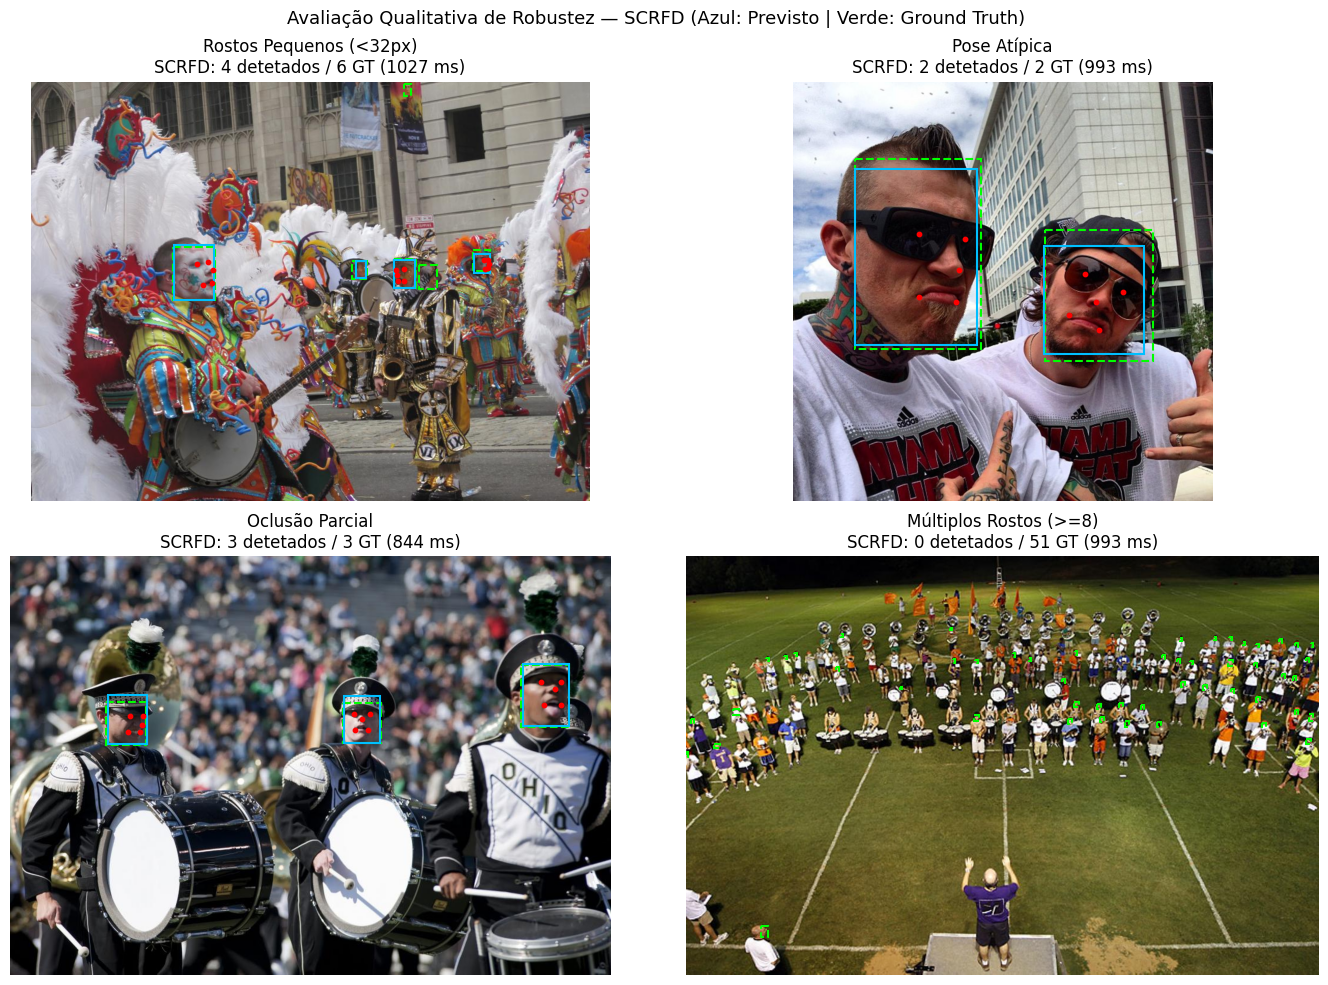

In [ ]:
# 1. Avaliação Quantitativa de Robustez (usando previsões já calculadas na Célula 2)
rob_scrfd = evaluate_detection_robustness(preds_scrfd, val_detailed, iou_threshold=0.5, small_thresh=32)
rob_retina = evaluate_detection_robustness(preds_retina, val_detailed, iou_threshold=0.5, small_thresh=32)

labels_pt = {
    "all_valid": "Todos (válidos)",
    "normal_size": "Tamanho normal (>=32px)",
    "small_faces": "Rostos pequenos (<32px)",
    "atypical_pose": "Pose atípica",
    "partial_occlusion": "Oclusão parcial",
    "heavy_occlusion": "Oclusão pesada",
    "multiple_faces": "Múltiplos rostos (>=5)",
}

print(f"{'Condição (WIDER FACE)':<26} | {'N Rostos':<8} | {'Recall SCRFD':<14} | {'Recall RetinaFace'}")
print("-" * 72)
for key, label in labels_pt.items():
    n_gt = rob_scrfd[key]["total"]
    r_s = rob_scrfd[key]["recall"]
    r_r = rob_retina[key]["recall"]
    print(f"{label:<26} | {n_gt:<8d} | {r_s:<14.4f} | {r_r:.4f}")

# 2. Avaliação Qualitativa: selecionar 1 imagem representativa por cenário difícil
scenarios = [
    ("Rostos Pequenos (<32px)", lambda fs: 2 <= len(fs) <= 8 and any(min(f["bbox"][2], f["bbox"][3]) < 32 for f in fs)),
    ("Pose Atípica", lambda fs: 1 <= len(fs) <= 4 and any(f["pose"] == 1 and min(f["bbox"][2], f["bbox"][3]) >= 32 for f in fs)),
    ("Oclusão Parcial", lambda fs: 1 <= len(fs) <= 4 and any(f["occlusion"] == 1 and min(f["bbox"][2], f["bbox"][3]) >= 32 for f in fs)),
    ("Múltiplos Rostos (>=8)", lambda fs: len(fs) >= 8),
]

selected_imgs = {}
used_paths = set()
for title, cond in scenarios:
    for img_path, faces_gt in val_detailed.items():
        valid_gt = [f for f in faces_gt if f["invalid"] == 0 and f["bbox"][2] > 0 and f["bbox"][3] > 0]
        if img_path not in used_paths and cond(valid_gt):
            selected_imgs[title] = (img_path, valid_gt)
            used_paths.add(img_path)
            break

# 3. Visualizar grelha 2x2 (Verde tracejado = Ground Truth | Azul = SCRFD | Vermelho = Landmarks)
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
for ax, (title, (img_path, valid_gt)) in zip(axs.flat, selected_imgs.items()):
    frame = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    det_faces, inf_ms = detector.detect(frame)

    ax.imshow(frame)
    for gt in valid_gt:
        x, y, w, h = gt["bbox"]
        ax.add_patch(patches.Rectangle((x, y), w, h, linewidth=1.5, edgecolor="lime", facecolor="none", linestyle="--"))

    for f in det_faces:
        x1, y1, x2, y2 = f["bbox"]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor="deepskyblue", facecolor="none"))
        if (x2 - x1) >= 25:  # mostrar landmarks apenas onde são legíveis
            xs = [pt[0] for pt in f["landmarks"]]
            ys = [pt[1] for pt in f["landmarks"]]
            ax.scatter(xs, ys, c="red", s=10)

    ax.set_title(f"{title}\nSCRFD: {len(det_faces)} detetados / {len(valid_gt)} GT ({inf_ms:.0f} ms)")
    ax.axis("off")

plt.suptitle("Avaliação Qualitativa de Robustez — SCRFD (Azul: Previsto | Verde: Ground Truth)", fontsize=13)
plt.tight_layout()
plt.show()

### 3. Teste de Alinhamento e Recorte Facial (*Face Crop*)
Esta etapa processa uma imagem de teste, extrai os 5 *landmarks* (olhos, nariz, boca) do detetor e aplica uma transformação afim. O resultado é um rosto geometricamente estabilizado e redimensionado (112x112), requisito obrigatório para extrair idade, género e expressão nas fases seguintes.

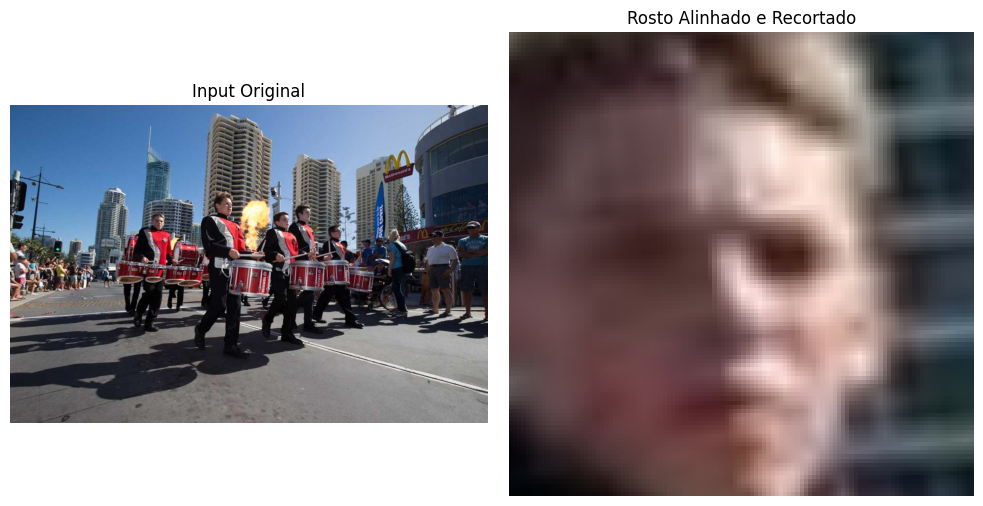

In [ ]:
aligner = FaceAligner(crop_size=112)

for img_path in val_annotations.keys():
    frame = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    faces, _ = detector.detect(frame)

    if len(faces) > 0:
        aligned_face = aligner.align(frame, faces[0]["landmarks"])

        fig, axs = plt.subplots(1, 2, figsize=(10, 5))
        axs[0].imshow(frame)
        axs[0].set_title("Input Original")
        axs[0].axis("off")

        axs[1].imshow(aligned_face)
        axs[1].set_title("Rosto Alinhado e Recortado")
        axs[1].axis("off")

        plt.tight_layout()
        plt.show()
        break
else:
    print("Nenhum rosto detetado na amostra atual.")

### 4. Avaliação de Idade e Género (UTKFace)
Esta célula processa o *dataset* UTKFace (versão já recortada e alinhada) através de amostragem estratificada por faixa etária. Os rótulos reais de idade e género são extraídos do nome de cada ficheiro (formato: `[age]_[gender]_[race]_[date&time].jpg`). No final, calculamos MAE, RMSE, MAE por faixa etária e Precision, Recall, F1-Score e Matriz de Confusão para o género (0 = Male, 1 = Female).

Total de imagens selecionadas (estratificadas): 200

=== Métricas Globais de Estimação de Idade Aparente ===
MAE:  16.37 anos
RMSE: 20.08 anos
Exatidão de Classificação por Faixa Etária: 25.00%

=== MAE por Faixa Etária ===
  Faixa 0-12  : MAE = 23.82 anos (n=40)
  Faixa 13-19 : MAE = 12.47 anos (n=40)
  Faixa 20-39 : MAE = 3.92 anos (n=40)
  Faixa 40-59 : MAE = 11.75 anos (n=40)
  Faixa 60+   : MAE = 29.88 anos (n=40)

=== Diferenças Demográficas (Idade e Género) ===
  Género Male  : MAE = 15.94 anos (n=104)
  Género Female: MAE = 16.83 anos (n=96)
  Grupo White  : MAE = 17.77 anos | Acc Género = 79.09% (n=110)
  Grupo Black  : MAE = 11.56 anos | Acc Género = 73.53% (n=34)
  Grupo Asian  : MAE = 23.33 anos | Acc Género = 80.00% (n=15)
  Grupo Indian : MAE = 14.38 anos | Acc Género = 68.97% (n=29)
  Grupo Others : MAE = 13.25 anos | Acc Género = 75.00% (n=12)

=== Classificação de Género — Todas as Previsões (0: Male, 1: Female) ===
Precision: Male=0.71, Female=0.87
Recall:    Male=0.9

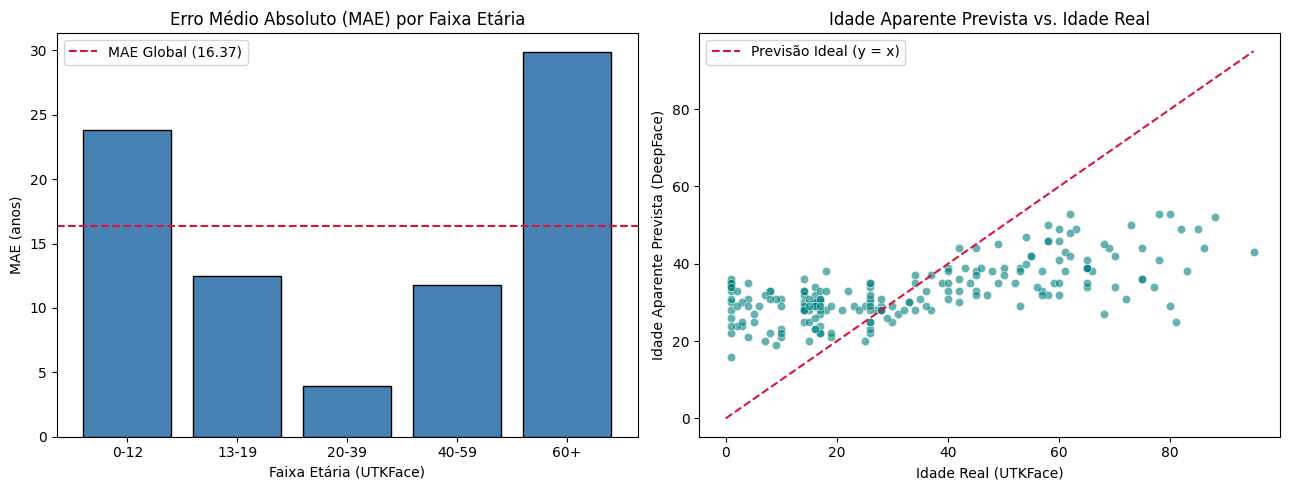

In [ ]:
# 1. Inicializar o estimador (DeepFace) com limiar de incerteza para género
estimator = AgeGenderEstimator(gender_conf_thresh=0.70)

# 2. Agrupar imagens válidas do UTKFace por faixa etária (incluindo anotação de race)
all_paths = glob.glob(os.path.join(cfg.utkface_img_dir, "*.jpg"))
bins = defaultdict(list)

for img_path in all_paths:
    parts = os.path.basename(img_path).split("_")
    if len(parts) < 4:
        continue
    try:
        age, gender, race = int(parts[0]), int(parts[1]), int(parts[2])
        if gender in (0, 1) and race in (0, 1, 2, 3, 4):
            bins[get_age_group(age)].append((img_path, age, gender, race))
    except ValueError:
        continue

# 3. Amostragem estratificada reprodutível (40 imagens por faixa = 200 no total)
random.seed(42)
samples_per_group = 40
sampled_data = [
    item
    for group in AGE_GROUPS
    for item in random.sample(bins[group], min(samples_per_group, len(bins[group])))
]
print(f"Total de imagens selecionadas (estratificadas): {len(sampled_data)}")

# 4. Executar inferência
y_true_age, y_pred_age = [], []
y_true_gender, y_pred_gender_raw, y_pred_gender_filt = [], [], []
y_true_race = []

for img_path, true_age, true_gender, true_race in sampled_data:
    frame_bgr = cv2.imread(img_path)
    if frame_bgr is None:
        continue

    attrs = estimator.estimate(frame_bgr)
    if attrs["age"] is not None:
        y_true_age.append(true_age)
        y_pred_age.append(attrs["age"])
        y_true_gender.append(true_gender)
        y_true_race.append(true_race)

        y_pred_gender_raw.append(0 if attrs["gender_raw"] == "Male" else 1)
        if attrs["gender"] == "Uncertain":
            y_pred_gender_filt.append(-1)
        else:
            y_pred_gender_filt.append(0 if attrs["gender"] == "Male" else 1)

# 5. Avaliar e apresentar métricas
utk_metrics = evaluate_age_gender_metrics(
    y_true_age,
    y_pred_age,
    y_true_gender,
    y_pred_gender_raw,
    y_pred_gender_filtered=y_pred_gender_filt,
    y_true_race=y_true_race,
)

print("\n=== Métricas Globais de Estimação de Idade Aparente ===")
print(f"MAE:  {utk_metrics['mae']:.2f} anos")
print(f"RMSE: {utk_metrics['rmse']:.2f} anos")
print(f"Exatidão de Classificação por Faixa Etária: {utk_metrics['age_group_accuracy']:.2%}")

print("\n=== MAE por Faixa Etária ===")
for group, (g_mae, n_samples) in utk_metrics["mae_by_group"].items():
    print(f"  Faixa {group:<6}: MAE = {g_mae:.2f} anos (n={n_samples})")

print("\n=== Diferenças Demográficas (Idade e Género) ===")
for g_name, (g_mae, n_s) in utk_metrics["mae_by_gender"].items():
    print(f"  Género {g_name:<6}: MAE = {g_mae:.2f} anos (n={n_s})")
for r_name, stats in utk_metrics["demo_by_race"].items():
    print(f"  Grupo {r_name:<7}: MAE = {stats['mae']:.2f} anos | Acc Género = {stats['gender_acc']:.2%} (n={stats['n']})")

p, r, f1 = utk_metrics["precision"], utk_metrics["recall"], utk_metrics["f1"]
print("\n=== Classificação de Género — Todas as Previsões (0: Male, 1: Female) ===")
print(f"Precision: Male={p[0]:.2f}, Female={p[1]:.2f}")
print(f"Recall:    Male={r[0]:.2f}, Female={r[1]:.2f}")
print(f"F1-Score:  Male={f1[0]:.2f}, Female={f1[1]:.2f}")
print("Matriz de Confusão:\n", utk_metrics["confusion_matrix"])

cg = utk_metrics["confident_gender"]
print(f"\n=== Filtragem por Incerteza (limiar >= {estimator.gender_conf_thresh:.2f}) ===")
print(f"Marcadas como 'Uncertain': {cg['n_uncertain']}/{len(y_true_gender)} ({cg['uncertain_rate']:.1%})")
print(f"Confiantes — Precision: Male={cg['precision'][0]:.2f}, Female={cg['precision'][1]:.2f}")
print(f"Confiantes — Recall:    Male={cg['recall'][0]:.2f}, Female={cg['recall'][1]:.2f}")
print(f"Confiantes — F1-Score:  Male={cg['f1'][0]:.2f}, Female={cg['f1'][1]:.2f}")
print("Matriz de Confusão (Confiantes):\n", cg["confusion_matrix"])

# 6. Gráficos de diagnóstico para o relatório
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

groups = list(utk_metrics["mae_by_group"].keys())
maes = [utk_metrics["mae_by_group"][g][0] for g in groups]
axs[0].bar(groups, maes, color="steelblue", edgecolor="black")
axs[0].axhline(utk_metrics["mae"], color="crimson", linestyle="--", label=f"MAE Global ({utk_metrics['mae']:.2f})")
axs[0].set_xlabel("Faixa Etária (UTKFace)")
axs[0].set_ylabel("MAE (anos)")
axs[0].set_title("Erro Médio Absoluto (MAE) por Faixa Etária")
axs[0].legend()

axs[1].scatter(y_true_age, y_pred_age, alpha=0.6, color="teal", edgecolors="white", linewidth=0.5)
max_age = max(max(y_true_age), max(y_pred_age))
axs[1].plot([0, max_age], [0, max_age], color="crimson", linestyle="--", label="Previsão Ideal (y = x)")
axs[1].set_xlabel("Idade Real (UTKFace)")
axs[1].set_ylabel("Idade Aparente Prevista (DeepFace)")
axs[1].set_title("Idade Aparente Prevista vs. Idade Real")
axs[1].legend()

plt.tight_layout()
plt.show()

> **Nota para o Relatório (Análise de Erro):** Na primeira iteração, o MAE de idade foi de 27.39 anos. Isto ocorreu devido ao problema do "Duplo Recorte". O modelo `buffalo_l` do InsightFace foi treinado para receber a imagem inteira, detetar o rosto internamente e aplicar as suas próprias margens e matriz afim. Como o dataset UTKFace (Cropped) forneceu um rosto já fortemente recortado, o detetor interno falhou a extração espacial, gerando distorções graves (*Domain Shift*) e degradando a estimativa da rede de atributos.

### 5. Reconhecimento e Avaliação de Expressões Faciais (BTFER)
Esta célula realiza uma avaliação *cross-dataset* no *dataset* BTFER (`btfer7`), organizado de forma equilibrada em 7 categorias de expressão facial (300 imagens por classe). Os rótulos reais são obtidos automaticamente a partir do nome de cada subpasta e harmonizados com as classes do modelo pré-treinado `EmotiEffLib` (`enet_b0_8_best_afew` em ONNX, treinado no AffectNet), restringindo a previsão às 7 categorias partilhadas (excluindo `Contempt`). Os resultados representam estimativas da configuração facial visível e não do estado emocional interno. No final, reportamos o **Macro-F1**, ***per-class recall***, **Matriz de Confusão** (além de *Overall/Balanced Accuracy* e *Macro Precision/Recall*) e o tempo médio de inferência por imagem.

Classes do modelo: ['Anger', 'Contempt', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']
Pasta raiz detetada: data/datasets/btfer\Batch_Ready 7
Classes do BTFER: ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']
Classes harmonizadas (comuns): ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']


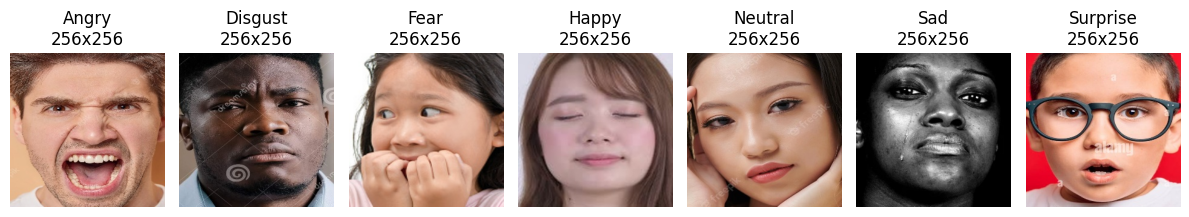


=== Avaliação Cross-Dataset no BTFER (n=2100 imagens) ===
Inferência média:  173.83 ms/imagem
Macro F1-Score:    0.7538
Overall Accuracy:  0.7571
Balanced Accuracy: 0.7571
Macro Precision:   0.7647
Macro Recall:      0.7571

=== Per-Class Recall (ordenado do menor para o maior) ===
  Sadness     : 0.6167
  Surprise    : 0.6300
  Disgust     : 0.6967
  Fear        : 0.7633
  Neutral     : 0.7700
  Anger       : 0.8533
  Happiness   : 0.9700

=== Top 5 Erros de Confusão (Real -> Previsto) ===
  Sadness      -> Neutral     : 78 imagens
  Surprise     -> Fear        : 67 imagens
  Disgust      -> Anger       : 42 imagens
  Neutral      -> Happiness   : 36 imagens
  Surprise     -> Happiness   : 33 imagens

Relatório Completo por Classe:
              precision    recall  f1-score   support

       Anger       0.73      0.85      0.79       300
     Disgust       0.87      0.70      0.77       300
        Fear       0.71      0.76      0.74       300
   Happiness       0.76      0.97      

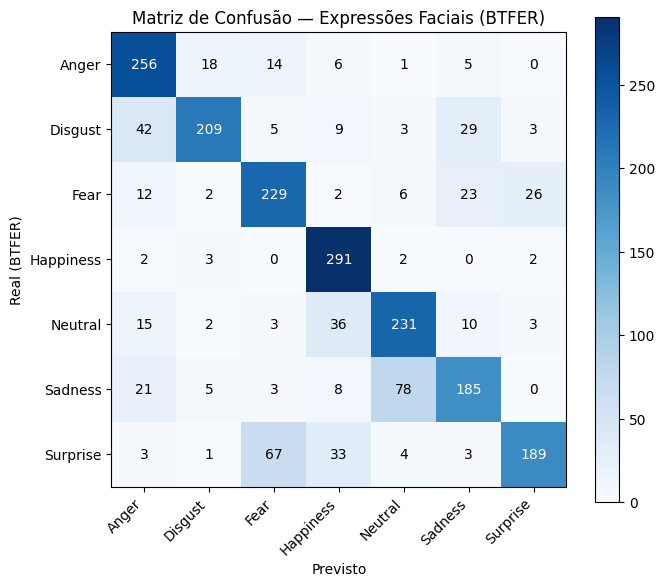

In [ ]:
# 1. Inicializar o modelo ONNX (pré-treinado no AffectNet)
expr_recognizer = ExpressionRecognizer(model_name=cfg.expression_model_name, device="cpu")
print("Classes do modelo:", expr_recognizer.classes)

# 2. Detetar pastas de classes do BTFER e harmonizar categorias
btfer_root = cfg.btfer_img_dir
class_dirs = [d for d in os.listdir(btfer_root) if os.path.isdir(os.path.join(btfer_root, d))]
if len(class_dirs) == 1:
    btfer_root = os.path.join(btfer_root, class_dirs[0])
    class_dirs = [d for d in os.listdir(btfer_root) if os.path.isdir(os.path.join(btfer_root, d))]

btfer_classes = sorted([canonicalize_expression(d) for d in class_dirs])
shared_classes = sorted(set(expr_recognizer.classes).intersection(btfer_classes))
print("Pasta raiz detetada:", btfer_root)
print("Classes do BTFER:", btfer_classes)
print("Classes harmonizadas (comuns):", shared_classes)

# 3. Inspeção visual de 4 amostras
sample_dirs = sorted(class_dirs)[:4]
fig, axs = plt.subplots(1, len(sample_dirs), figsize=(12, 3))
if len(sample_dirs) == 1:
    axs = [axs]
for ax, cls in zip(axs, sample_dirs):
    folder = os.path.join(btfer_root, cls)
    imgs = [p for ext in ("*.jpg", "*.png", "*.jpeg") for p in glob.glob(os.path.join(folder, ext))]
    if imgs:
        img = cv2.cvtColor(cv2.imread(imgs[0]), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(f"{cls}\n{img.shape[1]}x{img.shape[0]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# 4. Executar inferência em todo o BTFER (cross-dataset, sem fine-tuning)
y_true, y_pred = [], []
start_time = time.time()

for folder_name in class_dirs:
    true_label = canonicalize_expression(folder_name)
    if true_label not in shared_classes:
        continue

    folder_path = os.path.join(btfer_root, folder_name)
    img_paths = [p for ext in ("*.jpg", "*.png", "*.jpeg") for p in glob.glob(os.path.join(folder_path, ext))]

    for img_path in img_paths:
        frame_bgr = cv2.imread(img_path)
        if frame_bgr is None:
            continue
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        pred = expr_recognizer.predict(frame_rgb, allowed_classes=shared_classes)
        y_true.append(true_label)
        y_pred.append(pred["label"])

ms_per_img = ((time.time() - start_time) / len(y_true)) * 1000 if y_true else 0.0

# 5. Avaliar e apresentar métricas
expr_metrics = evaluate_expression_metrics(y_true, y_pred, labels=shared_classes)

print(f"\n=== Avaliação Cross-Dataset no BTFER (n={len(y_true)} imagens) ===")
print(f"Inferência média:  {ms_per_img:.2f} ms/imagem")
print(f"Macro F1-Score:    {expr_metrics['macro_f1']:.4f}")
print(f"Overall Accuracy:  {expr_metrics['overall_accuracy']:.4f}")
print(f"Balanced Accuracy: {expr_metrics['balanced_accuracy']:.4f}")
print(f"Macro Precision:   {expr_metrics['macro_precision']:.4f}")
print(f"Macro Recall:      {expr_metrics['macro_recall']:.4f}")

print("\n=== Per-Class Recall (ordenado do menor para o maior) ===")
for cls, rec in sorted(expr_metrics["per_class_recall"].items(), key=lambda x: x[1]):
    print(f"  {cls:<12}: {rec:.4f}")

print("\n=== Top 5 Erros de Confusão (Real -> Previsto) ===")
for count, real_cls, pred_cls in expr_metrics["top_confusions"]:
    print(f"  {real_cls:<12} -> {pred_cls:<12}: {count} imagens")

print("\nRelatório Completo por Classe:")
print(expr_metrics["classification_report"])

# 6. Visualizar Matriz de Confusão
cm = expr_metrics["confusion_matrix"]
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(shared_classes)))
ax.set_yticks(range(len(shared_classes)))
ax.set_xticklabels(shared_classes, rotation=45, ha="right")
ax.set_yticklabels(shared_classes)
ax.set_xlabel("Previsto")
ax.set_ylabel("Real (BTFER)")
ax.set_title("Matriz de Confusão — Expressões Faciais (BTFER)")

for i in range(len(shared_classes)):
    for j in range(len(shared_classes)):
        ax.text(
            j, i, str(cm[i, j]), ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )

plt.colorbar(im)
plt.tight_layout()
plt.show()

### 6. Reconhecimento de Identidade em Conjunto Fechado (ArcFace)
Esta célula avalia o módulo `IdentityRecognizer` sobre uma galeria local de voluntários com consentimento informado (< 20 identidades). Cada identidade registada é particionada de forma disjunta em **Registo (*Enrolment*)**, **Validação** (para calibração independente do limiar de similaridade de cosseno) e **Teste**. No final, reportamos a taxa de identificação **Rank-1** (*closed-set* e *open-set*), **FAR**, **FRR**, **taxa de rejeição de `"Unknown"`**, a **curva de sensibilidade ao limiar** e o impacto do **número de imagens de registo**.

In [ ]:
# 1. Inicializar reconhecedor ArcFace (galeria temporária em memória para avaliação)
id_recognizer = IdentityRecognizer(
    model_name=cfg.id_model_name,
    gallery_path=None,  # não sobrescrever a galeria de produção durante a avaliação
    similarity_threshold=cfg.id_similarity_thresh,
    max_identities=cfg.max_identities,
    use_gpu=False,
)

enrolled_dir = os.path.join(cfg.gallery_eval_dir, "enrolled")
unknowns_dir = os.path.join(cfg.gallery_eval_dir, "unknowns")

def extract_face_embedding_from_path(img_path):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        return None
    faces, _ = detector.detect(img_bgr)
    if not faces:
        return None
    # Selecionar o rosto de maior área
    best_face = max(faces, key=lambda f: (f["bbox"][2] - f["bbox"][0]) * (f["bbox"][3] - f["bbox"][1]))
    aligned_bgr = aligner.align(img_bgr, best_face["landmarks"])
    return id_recognizer.extract_embedding(aligned_bgr)

# 2. Extrair embeddings e particionar (Enrolment / Validação / Teste) sem fuga de dados
random.seed(42)
enrol_embs, val_known, test_known = {}, [], []

person_dirs = sorted(
    d for d in os.listdir(enrolled_dir) if os.path.isdir(os.path.join(enrolled_dir, d))
)
for person in person_dirs:
    folder = os.path.join(enrolled_dir, person)
    paths = [p for ext in ("*.jpg", "*.png", "*.jpeg") for p in glob.glob(os.path.join(folder, ext))]
    embs = [e for p in sorted(paths) if (e := extract_face_embedding_from_path(p)) is not None]
    if len(embs) < 4:
        print(f"[Aviso] '{person}' tem apenas {len(embs)} rostos detetados (mínimo recomendado: 4).")
        continue

    random.shuffle(embs)
    n_enrol = max(2, int(len(embs) * 0.5))
    n_val = max(1, (len(embs) - n_enrol) // 2)

    enrol_embs[person] = embs[:n_enrol]
    val_known.extend((person, e) for e in embs[n_enrol : n_enrol + n_val])
    test_known.extend((person, e) for e in embs[n_enrol + n_val :])

# Extrair embeddings dos desconhecidos e dividir 50/50 (Validação / Teste)
unk_paths = [p for ext in ("*.jpg", "*.png", "*.jpeg") for p in glob.glob(os.path.join(unknowns_dir, ext))]
unk_embs = [e for p in sorted(unk_paths) if (e := extract_face_embedding_from_path(p)) is not None]
random.shuffle(unk_embs)
mid_unk = len(unk_embs) // 2
val_unknown = [("Unknown", e) for e in unk_embs[:mid_unk]]
test_unknown = [("Unknown", e) for e in unk_embs[mid_unk:]]

print(f"Identidades registadas: {len(enrol_embs)} ({list(enrol_embs.keys())})")
print(f"Validação: {len(val_known)} conhecidos + {len(val_unknown)} desconhecidos")
print(f"Teste:     {len(test_known)} conhecidos + {len(test_unknown)} desconhecidos")

# 3. Registar templates médios de Enrolment
id_recognizer.clear_gallery(delete_file=False)
for person, embs in enrol_embs.items():
    id_recognizer.enrol_from_embeddings(person, embs, consent_given=True, save=False)

# 4. Calibrar limiar EXCLUSIVAMENTE na Validação
val_known_sims = [id_recognizer.identify_embedding(e, threshold=0.0)["similarity"] for _, e in val_known]
val_unk_sims = [id_recognizer.identify_embedding(e, threshold=0.0)["similarity"] for _, e in val_unknown]

calib = calibrate_identity_threshold(val_known_sims, val_unk_sims)
best_thresh = calib["best_threshold"]
print(f"\n=== Calibração do Limiar (Conjunto de Validação) ===")
print(f"Limiar ótimo calibrado: {best_thresh:.3f} (EER ≈ {calib['eer']:.4f} em t={calib['eer_threshold']:.3f})")

# 5. Avaliar no Conjunto de Teste (intocado durante a calibração)
test_probes = test_known + test_unknown
y_true, y_pred_open, y_pred_closed, test_sims = [], [], [], []

for true_name, emb in test_probes:
    res = id_recognizer.identify_embedding(emb, threshold=best_thresh)
    y_true.append(true_name)
    y_pred_open.append(res["identity"])
    y_pred_closed.append(res["best_match"])
    test_sims.append(res["similarity"])

id_metrics = evaluate_identity_metrics(y_true, y_pred_open, y_pred_closed, test_sims)

print(f"\n=== Avaliação Final de Identidade (Conjunto de Teste, limiar={best_thresh:.3f}) ===")
print(f"Closed-Set Rank-1 (conhecidos): {id_metrics['closed_set_rank1']:.2%}")
print(f"Open-Set Rank-1 / DIR:          {id_metrics['open_set_rank1']:.2%}")
print(f"FRR (falsas rejeições):         {id_metrics['frr']:.2%}")
print(f"Taxa de troca entre conhecidos: {id_metrics['false_id_rate']:.2%}")
print(f"FAR (falsas aceitações):        {id_metrics['far']:.2%}")
print(f"Taxa de rejeição 'Unknown':     {id_metrics['unknown_rejection_rate']:.2%}")

# 6. Impacto do número de imagens de registo (k = 1 até min_enrol)
max_k = min(len(v) for v in enrol_embs.values())
k_values, k_open_r1, k_mean_sim = [], [], []

for k in range(1, max_k + 1):
    id_recognizer.clear_gallery(delete_file=False)
    for person, embs in enrol_embs.items():
        id_recognizer.enrol_from_embeddings(person, embs[:k], consent_given=True, save=False)

    correct, sims_k = 0, []
    for true_name, emb in test_known:
        res = id_recognizer.identify_embedding(emb, threshold=best_thresh)
        sims_k.append(res["similarity"])
        if res["identity"] == true_name:
            correct += 1

    k_values.append(k)
    k_open_r1.append(correct / len(test_known) if test_known else 0.0)
    k_mean_sim.append(float(np.mean(sims_k)) if sims_k else 0.0)

print("\n=== Efeito do Número de Imagens de Registo (k) ===")
for k, r1, sim in zip(k_values, k_open_r1, k_mean_sim):
    print(f"  k={k} imagem(ns)/pessoa: Open-Set Rank-1 = {r1:.2%} | Similaridade média = {sim:.4f}")

# 7. Gráficos para o relatório (Sensibilidade ao Limiar + Efeito de k)
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

axs[0].plot(id_metrics["thresholds"], id_metrics["far_curve"], label="FAR (Falsa Aceitação)", color="crimson", lw=2)
axs[0].plot(id_metrics["thresholds"], id_metrics["frr_curve"], label="FRR (Falsa Rejeição)", color="steelblue", lw=2)
axs[0].plot(id_metrics["thresholds"], id_metrics["dir_curve"], label="Open-Set Rank-1 (DIR)", color="seagreen", lw=2, linestyle="--")
axs[0].axvline(best_thresh, color="black", linestyle=":", label=f"Limiar calibrado ({best_thresh:.2f})")
axs[0].set_xlabel("Limiar de Similaridade de Cosseno")
axs[0].set_ylabel("Taxa")
axs[0].set_title("Sensibilidade ao Limiar de Identificação (Teste)")
axs[0].grid(alpha=0.3)
axs[0].legend()

axs[1].plot(k_values, k_open_r1, marker="o", color="seagreen", lw=2, label="Open-Set Rank-1")
axs[1].plot(k_values, k_mean_sim, marker="s", color="darkorange", lw=2, label="Similaridade Média (Conhecidos)")
axs[1].set_xticks(k_values)
axs[1].set_ylim(0, 1.05)
axs[1].set_xlabel("Número de Imagens de Registo por Pessoa (k)")
axs[1].set_ylabel("Valor")
axs[1].set_title("Impacto do Número de Imagens de Registo")
axs[1].grid(alpha=0.3)
axs[1].legend()

plt.tight_layout()
plt.show()